## sNQS | Implementation of Fourier Modes ##

As defined in the paper of Wang et al. (2026), Smooth Neural Network Quantum States (sNQS) involve defining a neural network's variational parameters as linear combinations of temporal basis functions with time-independent variational parameters.. This implementation as a method for simulating the dynamics of quantum systems offers certain advantages over previously established methods. Notably, this allows us to use fewer parameters to achieve desired expressivity. Further, by using temporal basis functions and matching derivatives to the n-th degree, we can enforce the smooth parametrization, ensuring the function is initialized well and stable throughout optimization.

### Defining the Fourier Basis ###

By definition, we can write the Fourier basis in both a trigonometric and exponential form
$$\mathcal{T}_q = a_q \cos(q\omega_0 t) + b_q \sin(q \omega_0 t)$$
$$\mathcal{T}_q = c_q \cdot e^{-i q\omega_0 t}$$

Since the exponential form will offer expressivity in the form of the complex basis, as well as having a trivial-to-compute derivative, we select it for the implementation of Fourier Modes. In addition, this will allow us to optimize only the $c_n$ parameter, instead of having a separate $a_n$ and $b_n$ for each of the modes. In particular, we define:

$$\mathcal{T}_q = e^{-i q\omega_0 t}$$

Where we instead define $c_q = \theta_{j,q}$, our trainable parameter. The exponential also offers another advantage in line with this method by trivializing the derivative. The general form of the derivative for this is as follows:

$$\frac{d^n}{dt^n}\mathcal{T}_q = (-iq\omega_0)^n \cdot e^{-i q\omega_0 t}$$

This form is trivial to compute, allowing us to scale up $Q$ to higher order for increased expressivity with less strain on our computational constraints, especially for the continuity matching step. In the next blocks, we will introduce the implementation of these ideas in code.

### Selection of $\omega_0$ ###

The definition of the $\omega_0$ is a crucial decision, as it defines the fundamental frequency of our Fourier basis, thereby affecting the frequency domain of our wavefunction representation. In short, this affects how expressive our neural network is and how well it is able to represent the desired wavefunction.

Initially, we select the quasiparticle dispersion relation for the 1D TFIM as follows:
$$
\epsilon_0 = 2 \sqrt{J^2 + h_x^2 - 2(Jh_x)\cos(k)}
$$
where we define $k = \frac{2\pi q}{Q}$ to span our representative basis. Scaling this to become $\omega_0$, we have:
$$
\omega = 2 \cdot \pi \cdot 2 \sqrt{J^2 + h_x^2 - 2(Jh_x)\cos(k)} = 2\pi\epsilon_0
$$

In [ ]:
import math
import torch as tc

def _fourier_mode(t, Q, J, hx, hz, device="cpu") -> tc.Tensor:
    dtype = tc.complex128
    t = tc.as_tensor(t, dtype=dtype, device=device)
    t_real = t.real
    t_imag = t.imag
    qs = tc.arange(Q, device=device)

    # omega_0 = 2 * math.pi / (tW * Q)
    k = math.pi / Q
    omega_0 = (2 * math.pi * J * math.sqrt(1 + (hx / J) ** 2 - 2 * (hx / J) * math.cos(k)))

    # exp implementation
    if t.ndim == 0:
        g_qt = tc.empty(Q, dtype=dtype, device=device)
        g_qt[0] = 1.0 + 0.0j
        if Q > 1:
            g_qt[1:] = (tc.exp(-1j * t * qs[1:] * omega_0))
        return g_qt
    elif t.ndim == 1:
        Nt = t.numel()
        g_qt = tc.empty((Q, Nt), dtype=dtype, device=device)
        g_qt[0, :] = 1.0 + 0.0j
        if Q > 1:
            g_qt[1:] = ((tc.exp(-1j * t[None, :] * qs[1:, None] * omega_0)))
        print("running check: ", g_qt)
        return g_qt

In [3]:
!git clone https://github.com/theurile/sNQS-thomas-

Cloning into 'sNQS-thomas-'...
remote: Enumerating objects: 87, done.
remote: Counting objects: 100% (21/21), done.
remote: Compressing objects: 100% (19/19), done.
remote: Total 87 (delta 3), reused 14 (delta 2), pack-reused 66 (from 3)
Receiving objects: 100% (87/87), 70.18 MiB | 11.20 MiB/s, done.
Resolving deltas: 100% (11/11), done.


In [7]:
%pip install git+https://github.com/zhuhaodavid/quante.git

  Cloning https://github.com/zhuhaodavid/quante.git to /tmp/pip-req-build-x3jpiix3
  Running command git clone --filter=blob:none --quiet https://github.com/zhuhaodavid/quante.git /tmp/pip-req-build-x3jpiix3
  Resolved https://github.com/zhuhaodavid/quante.git to commit 144b86b203c5c6ee76a4966bbcbe95ced33e400d
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 122.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 100.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.6/41.6 kB 4.8 MB/s eta 0:00:00
  Created wheel for quante: filename=quante-0.3.0-py3-none-any.whl size=469356 sha256=28ca7918d51208712fd255b702eeff9be041b60aea5289811d95f456ab5b9ffe
  Stored in directory: /tmp/pip-ephem-wheel-cache-h9kxn6vv/wheels/0f/4d/08/70849a1b58107172b7b27f372cdd41ab8517ee3015bd8c5730
Successfully built quante


In [4]:
%cd sNQS-thomas-
!git fetch --all
!git reset --hard origin/main

/content/sNQS-thomas-


%pip install numpy torch matplotlib git+https://github.com/zhuhaodavid/quante.git IPython

In [8]:
!python  run_lpe_job.py --dt 0.1 --tK 2.0

job=lpe_dt0p1_tK2
output=/content/sNQS-thomas-/results/lpe_grid/N10_lpe_order4_epochs2000_adamw.h5::dt=0.1/tK=2
parameters: N=10, LPE order=4, epochs=1500, dt=0.1, tK=2, optimizer=adamw
--------------------
Getting initial state...
vmc-ing 
  0% 0/1000 [00:00<?, ?it/s]Epoch    1/1000, ⟨H⟩=-10.0000479266
 73% 727/1000 [00:14<00:05, 53.16it/s]Epoch  733/1000, ⟨H⟩=-10.0000000000, ⟨Sx⟩=10.00000000, ⟨Sz⟩=-0.07600000
 73% 732/1000 [00:14<00:05, 50.02it/s]
assigning theta 
getting coeffs 
----------- COEFFS -----------
tensor([0.0000+0.0000j, 0.0043+0.0395j, 0.0085+0.0000j, 0.0543+0.0235j,
        0.1000+0.0000j, 0.1043+0.0395j, 0.1085+0.0000j, 0.1543+0.0235j,
        0.2000+0.0000j, 0.2043+0.0395j, 0.2085+0.0000j, 0.2543+0.0235j,
        0.3000+0.0000j, 0.3043+0.0395j, 0.3085+0.0000j, 0.3543+0.0235j,
        0.4000+0.0000j, 0.4043+0.0395j, 0.4085+0.0000j, 0.4543+0.0235j,
        0.5000+0.0000j, 0.5043+0.0395j, 0.5085+0.0000j, 0.5543+0.0235j,
        0.6000+0.0000j, 0.6043+0.0395j, 0.6085+0.0

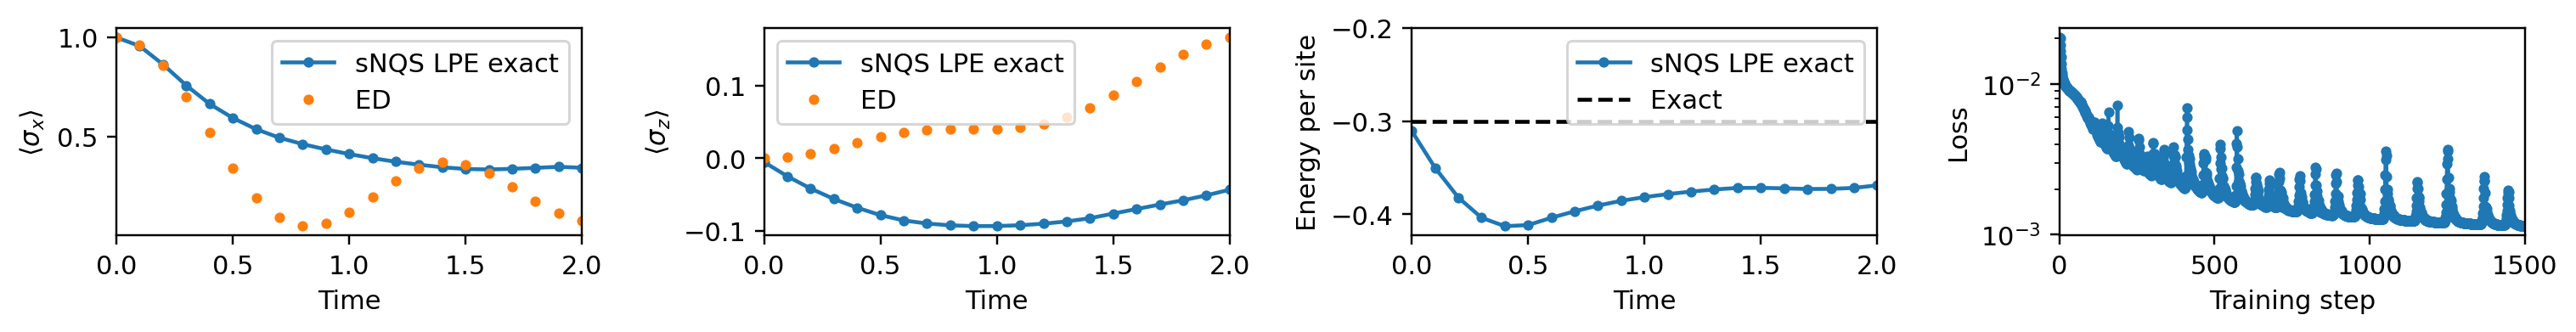

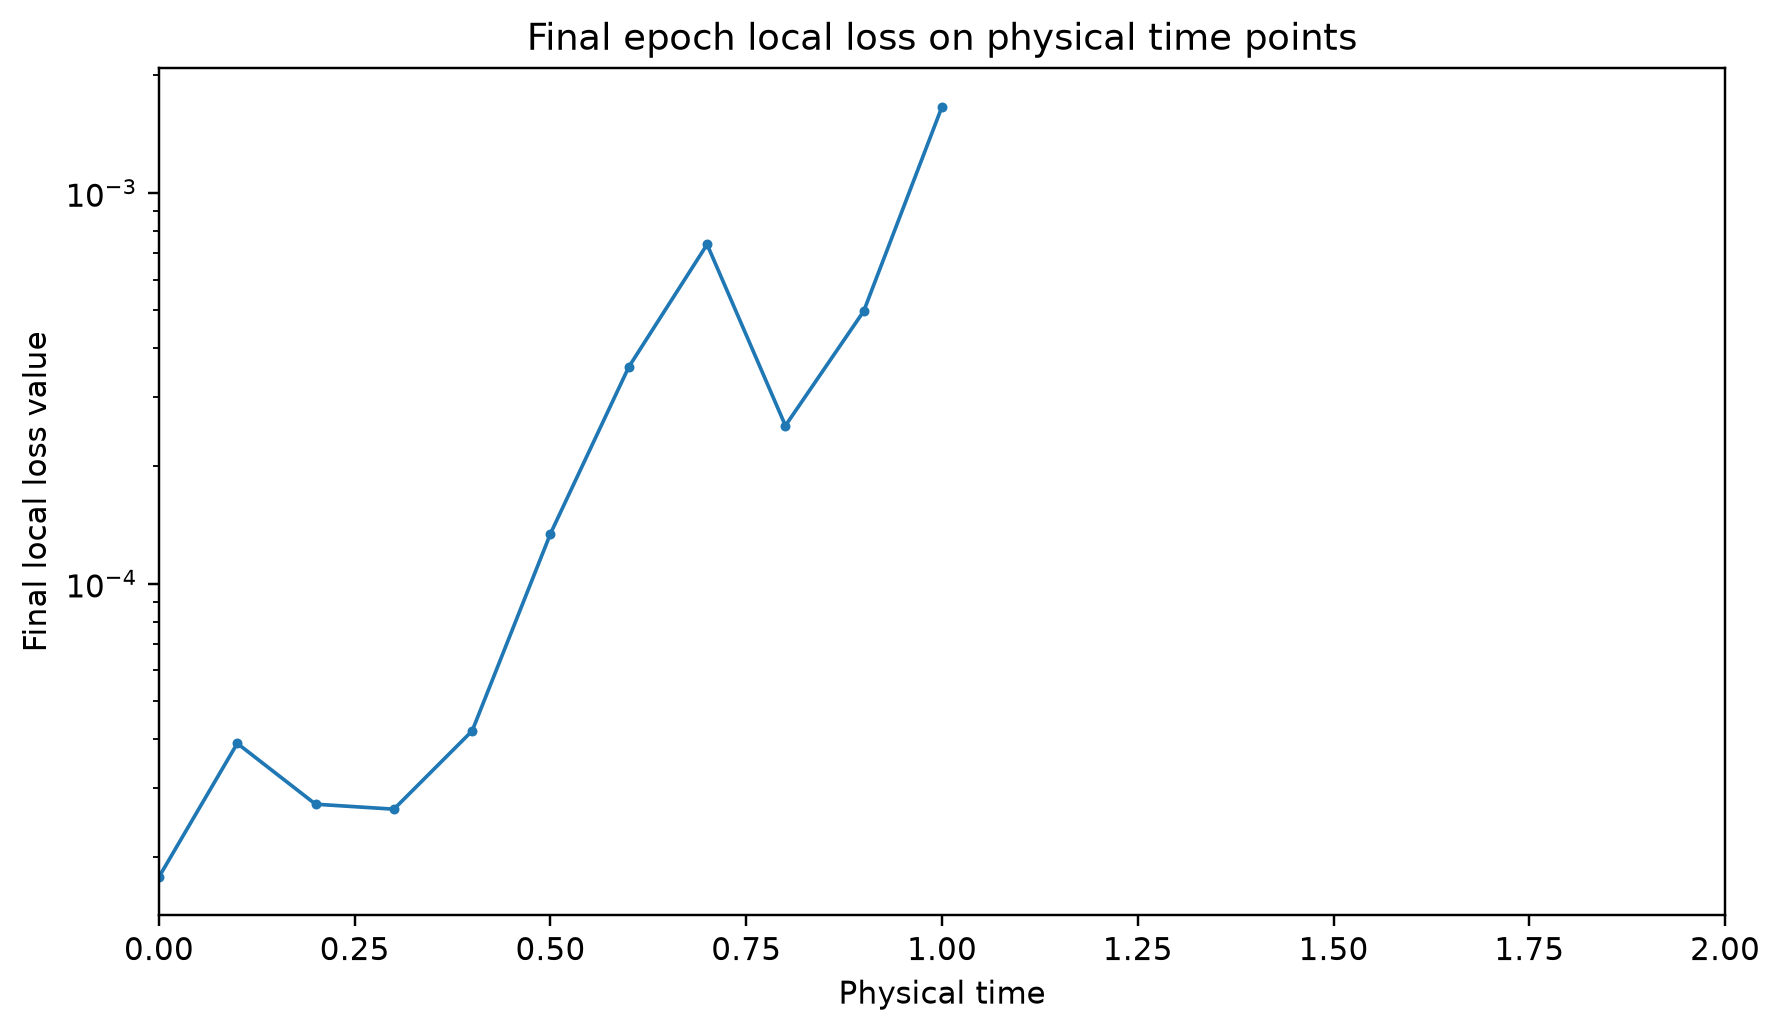

In [9]:
from IPython.display import Image, display

display(Image(filename="/content/sNQS-thomas-/results/lpe_grid/figures/lpe_dt0p1_tK2_summary.png"))
display(Image(filename="/content/sNQS-thomas-/results/lpe_grid/figures/lpe_dt0p1_tK1_loss_values.png"))